# CIFAR-10 Image Classification with a Multi-Kernel Attention CNN

A custom convolutional network whose blocks run 1×1, 3×3, 5×5 and 7×7 convolutions in parallel and learn, per input, how much to trust each kernel size. Trained with AutoAugment, label smoothing, mixed precision and cosine warm restarts; hyperparameters from an Optuna search.

**Result: 92.05% test accuracy.**


# Library Imports

In [ ]:
# Final CIFAR-10 Training with Tuned Hyperparameters
# installing required packages for the notebook
# pip install torch torchvision matplotlib tqdm
# importing all necessary libraries for training, evaluation and visualization

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.transforms.autoaugment as autoaugment
from torch.utils.data import DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np
import random
import os

In [2]:
# setting fixed random seeds for reproducibility
# torch.manual_seed(42)
# np.random.seed(42)
# random.seed(42)

# setting device configuration to use gpu if available else cpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## Data Transforms

Before feeding the images to the model, I applied several transformations on the training set to increase the diversity of the data and make the model more robust. Especially in image classification tasks like CIFAR-10, data augmentation is super important to help the model generalize well instead of just memorizing the training data.

In the training pipeline, I used:

-   RandomCrop(32, padding=4): This randomly crops a 32x32 patch from the image but first adds a padding of 4 pixels around it. This helps the model learn to recognize objects even if they slightly shift or change position.

-   RandomHorizontalFlip(): This flips the image horizontally with a 50% chance. It's a simple but very effective trick because in real life, objects can appear flipped or mirrored.

-   AutoAugment(CIFAR10 Policy): AutoAugment automatically applies a set of learned augmentation policies that were found to work well specifically for CIFAR-10. This adds more complex variations like color changes, brightness adjustments, or small geometric distortions.

-   ToTensor(): Converts the image from a PIL format (0-255 pixel values) to a PyTorch tensor with values between 0 and 1.

-   Normalize((0.5,), (0.5,)): Finally, I normalize the images so that pixel values are centered around 0, typically in the range [-1, 1]. This helps the model converge faster and more stably during training.

For the test set, I didn’t apply any augmentation because we want to test the model on clean, untouched images. The only transformation here is normalization — just to make sure that the input format matches what the model saw during training.

In [3]:
#Data Transforms
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    autoaugment.AutoAugment(autoaugment.AutoAugmentPolicy.CIFAR10),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Dataset Preparation

## Load CIFAR-10 Dataset

For this project, I worked with the CIFAR-10 dataset, which is kind of a classic go-to dataset in image classification tasks. It has 60,000 color images divided into 10 different classes like airplane, car, dog, cat, etc.

When loading the dataset, I handled the train and test sets a bit differently, because their purpose is different.

In the training set, I applied the data augmentations I explained earlier, and I also shuffled the data at every epoch. Shuffling is crucial during training because it prevents the model from relying on the order of the data.

For the test set, since I want to measure the true performance of the model on unseen data, I only applied normalization without any augmentation, and no shuffle here because order doesn’t matter during evaluation.

A few important settings I used while loading the data:

-   Batch size is 128 → meaning the model processes 128 images at a time.

-   shuffle=True for the training set → randomizes the order every epoch.

-   shuffle=False for the test set → keeps it stable.

-   Used num_workers=2 → this just helps loading the data faster using 2 CPU threads in parallel.


In [4]:
# Load Dataset
batch_size = 128
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)
train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
test_loader = DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

## Network Architecture Blocks

The overall structure of my model is pretty modular and clean. The idea is to progressively extract more abstract features from the input image and then classify it.

There are basically two main types of blocks I used while building this architecture:

-   The first one is what I called IntermediateBlock. It’s basically a block that applies several convolution layers with different kernel sizes like 1x1, 3x3, 5x5, and 7x7. All of them process the input at the same time. Then, instead of just summing or concatenating them, I added a small attention mechanism that learns which kernel size to trust more for that specific input.

-   The second important piece is the OutputBlock. After all the feature extraction is done, this block takes the output and passes it through a few fully connected layers with dropout. This is mainly for classification — turning those feature maps into class scores.

Finally, the full model called CustomNet is just stacking 4 of those IntermediateBlocks one after another — increasing the number of filters each time — and at the very end, it connects to the OutputBlock for making the final prediction.

This kind of architecture is nice for CIFAR-10 because it’s flexible — it allows the model to decide whether small details or larger patterns matter more in a given image.


In [5]:
# network architecture blocks
class IntermediateBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_sizes=[3, 5, 7, 1]):
        super().__init__()
        self.convs = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=k, padding=k//2),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True)
            ) for k in kernel_sizes
        ])
        self.fc = nn.Linear(in_channels, len(kernel_sizes))
        self._initialize_weights()

    def forward(self, x):
        B, C, H, W = x.shape
        m = x.mean(dim=(2, 3))
        a = torch.softmax(self.fc(m), dim=1)
        conv_outs = torch.stack([conv(x) for conv in self.convs], dim=1)
        a = a.view(B, -1, 1, 1, 1)
        out = (a * conv_outs).sum(dim=1)
        return out

    def _initialize_weights(self):
        for m in self.convs:
            for layer in m:
                if isinstance(layer, nn.Conv2d):
                    nn.init.kaiming_normal_(layer.weight, mode='fan_out', nonlinearity='relu')
                    if layer.bias is not None:
                        nn.init.constant_(layer.bias, 0)

class OutputBlock(nn.Module):
    def __init__(self, in_channels, dropout=0.2887, num_classes=10):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(in_channels, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )
        self._initialize_weights()

    def forward(self, x):
        return self.fc(x.mean(dim=(2, 3)))

    def _initialize_weights(self):
        for m in self.fc:
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                nn.init.constant_(m.bias, 0)

class CustomNet(nn.Module):
    def __init__(self, dropout):
        super().__init__()
        self.blocks = nn.Sequential(
            IntermediateBlock(3, 32),
            IntermediateBlock(32, 64),
            IntermediateBlock(64, 128),
            IntermediateBlock(128, 256),
        )
        self.output = OutputBlock(256, dropout=dropout)

    def forward(self, x):
        return self.output(self.blocks(x))

## Label Smoothing Cross-Entropy Loss

To prevent the model from becoming overly confident, we use *label smoothing*, which distributes a small portion of the target probability mass across all classes.

This loss:
- Reduces overfitting
- Encourages better generalization
- Improves calibration of predicted probabilities


In [6]:
# label smoothing loss
class LabelSmoothingCrossEntropy(nn.Module):
    def __init__(self, smoothing=0.1):
        super().__init__()
        self.smoothing = smoothing
    def forward(self, pred, target):
        confidence = 1.0 - self.smoothing
        log_probs = nn.functional.log_softmax(pred, dim=-1)
        true_dist = torch.zeros_like(log_probs).scatter_(1, target.unsqueeze(1), confidence)
        true_dist += self.smoothing / pred.size(1)
        return torch.mean(torch.sum(-true_dist * log_probs, dim=-1))

# Evaluation Function

This utility function evaluates model performance on a given dataset loader (train or test) by:

- Switching the model to evaluation mode (model.eval())
- Disabling gradient computation with torch.no_grad() for efficiency
- Calculating total number of correct predictions
- Returning accuracy as a percentage



In [7]:
# eval func
def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            pred = out.argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)
    return 100 * correct / total

# Training Loop

This function handles the full training process for the model, including:

- Mixed precision training with `torch.cuda.amp` for efficiency
- Logging and updating model performance
- Early stopping based on patience
- Saving the best model based on test accuracy

Returns:
- Training accuracies per epoch
- Test accuracies per epoch
- Batch-wise training losses
- Best test accuracy


In [8]:
# training Loop
def train_model(model, optimizer, scheduler, criterion, epochs=180, patience=20):
    scaler = torch.cuda.amp.GradScaler()
    best_acc, wait = 0, 0
    train_accs, test_accs, losses = [], [], []

    for epoch in range(epochs):
        model.train()
        correct, total, loss_sum = 0, 0, 0
        loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
        for x, y in loop:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            with torch.cuda.amp.autocast():
                out = model(x)
                loss = criterion(out, y)
                pred = out.argmax(dim=1)
                correct += (pred == y).sum().item()
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            total += y.size(0)
            loss_sum += loss.item()
            loop.set_postfix(loss=loss_sum/(total/batch_size), acc=100*correct/total)
            losses.append(loss.item())

        train_acc = 100 * correct / total
        test_acc = evaluate(model, test_loader)
        train_accs.append(train_acc)
        test_accs.append(test_acc)
        scheduler.step()

        print(f"Epoch {epoch+1}: Train Acc={train_acc:.2f}% | Test Acc={test_acc:.2f}%")
        if test_acc > best_acc:
            best_acc = test_acc
            wait = 0
            torch.save(model.state_dict(), "best_model.pth")
            print(f"New best model saved with Test Acc: {test_acc:.2f}%")
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping.")
                break

    return train_accs, test_accs, losses, best_acc

## Train Final Model

Now that we've obtained the best hyperparameters from our Optuna hyperparameter search, we train the final model using those values for:

- Learning rate
- Momentum
- Weight decay
- Dropout rate

We train for 200 epochs with a patience of 20 for early stopping and save the best model during training.


In [9]:
# train Final Model
best_params = {'lr': 0.027683303583751914, 'momentum': 0.9605588563675064, 'weight_decay': 6.211008067657561e-05, 'dropout': 0.2886594040349749}
model = CustomNet(dropout=best_params["dropout"]).to(device)
criterion = LabelSmoothingCrossEntropy()
optimizer = optim.SGD(model.parameters(), lr=best_params["lr"], momentum=best_params["momentum"], weight_decay=best_params["weight_decay"])
scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10)

train_accs, test_accs, losses, _ = train_model(model, optimizer, scheduler, criterion, epochs=200, patience=20)

Epoch 1: Train Acc=23.08% | Test Acc=32.64%
New best model saved with Test Acc: 32.64%


Epoch 2: Train Acc=31.81% | Test Acc=34.83%
New best model saved with Test Acc: 34.83%


Epoch 3: Train Acc=39.17% | Test Acc=47.79%
New best model saved with Test Acc: 47.79%


Epoch 4: Train Acc=44.61% | Test Acc=36.70%


Epoch 5: Train Acc=50.40% | Test Acc=58.33%
New best model saved with Test Acc: 58.33%


...

Epoch 136: Train Acc=89.59% | Test Acc=89.80%


Epoch 137: Train Acc=90.70% | Test Acc=90.46%


Epoch 138: Train Acc=91.94% | Test Acc=91.06%


Epoch 139: Train Acc=92.45% | Test Acc=91.99%


Epoch 140: Train Acc=92.83% | Test Acc=92.03%
Early stopping.


## Final Evaluation

After training, we load the best model saved during training (based on highest test accuracy) and evaluate it on the CIFAR-10 test set to report the final accuracy. This ensures we are using the most performant model checkpoint.


In [10]:
#final evaluation
model.load_state_dict(torch.load("best_model.pth"))
final_test_acc = evaluate(model, test_loader)
print(f"Final Test Accuracy: {final_test_acc:.2f}%")

Final Test Accuracy: 92.05%


## Plotting Training Loss

We visualize how the loss changes over each training batch.

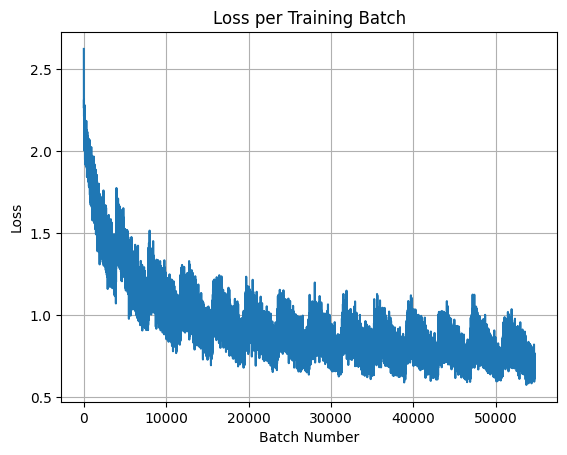

In [11]:
# plotting
plt.figure()
plt.plot(losses)
plt.title("Loss per Training Batch")
plt.xlabel("Batch Number")
plt.ylabel("Loss")
plt.grid(True)
plt.savefig("loss_per_batch.png")
plt.show()

## Accuracy per Epoch

This plot visualizes how the model's accuracy evolves across epochs for both the training and test sets. It helps evaluate learning progress and potential overfitting over time.


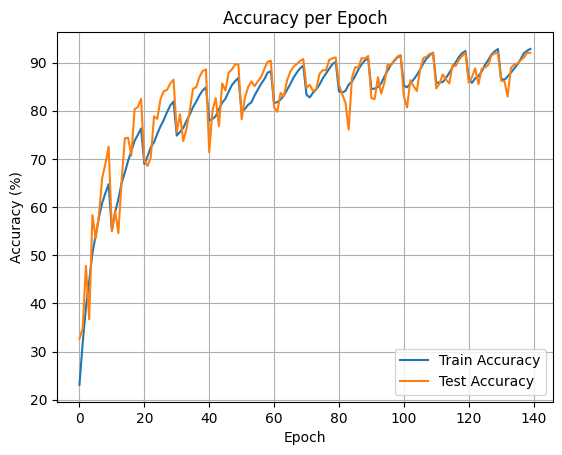

In [12]:
plt.figure()
plt.plot(train_accs, label='Train Accuracy')
plt.plot(test_accs, label='Test Accuracy')
plt.title("Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.savefig("accuracy_per_epoch.png")
plt.show()